# Lesson 17. When one splat cannot do the job

[Course plan](../../README.md)

The target has two blue beads with a pale gap between them. The model has a single broad splat and an almost transparent speck off to the side. We can move the broad splat or fade it. Its horizontal slice still has one peak where the target has two. Sometimes the next useful move is a change to the list of Gaussians itself.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## One starting point, several possible moves

The camera, color, and background stay fixed. The target is on the left, the model on the right. Separate operations can copy a selected splat, replace it with two children, remove faint splats, or reduce all opacities together. Returning to the starting scene lets us compare these moves from a common reference. An ordinary gradient step moves centers horizontally and changes their opacity.

Each comparison has three different readings. MSE measures color discrepancies across 33 × 33 pixels. Splat count measures the length of the list. The byte count includes just the numerical scene parameters stored in float32. An edit that takes more space and makes the image worse is an informative outcome too.

In [2]:
display(demo.experiment(17, "en"))

## A step inside the list

Initially the list holds two splats. The broad one has $x=-0.16$, horizontal scale $s_x=0.63$, and center opacity $o=0.77$. A small shift changes the frame's RGB and its error. For the two derivatives we take two neighboring measurements apiece, starting each from the same original state as in the previous lesson. We get $g_x\approx-0.00304635$ MSE per unit of length and $g_o\approx0.00834045$ per unit of opacity.

At learning rate $\eta=3$, the new coordinate is $x'=-0.16-3(-0.00304635)\approx-0.15086$. The new opacity is $o'=0.77-3(0.00834045)\approx0.74498$. The splat moves right and becomes a touch paler on white. The small splat gets its own two derivatives. After the simultaneous update MSE falls from $0.00467723$ to $0.00446188$. Indices 0 and 1 still refer to the same two splats. The gradient of a value in row 0 cannot create row 2.

In [3]:
initial = sr.density_scene()
print(np.round(sr.density_gradients(initial), 7))
updated = sr.density_step(initial)
print(updated["splats"][0]["center"], updated["splats"][0]["opacity"])
assert len(initial["splats"]) == len(updated["splats"]) == 2
assert sr.density_loss(updated) < sr.density_loss(initial)

[[-3.0463e-03  8.3405e-03]
 [ 4.5300e-05 -5.5900e-05]]
[-0.1508609595795733, 0, 4] 0.7449786379339152


## A clone darkens the image. A split changes its shape

A **clone** appends a copy of the center, shape, color, and opacity. At the original splat center $\alpha=0.77$, so $1-0.77=0.23$ of the background passed through. Two identical layers pass $0.23\cdot0.23=0.0529$, making their combined opacity $1-0.0529=0.9471$. Identical coordinates therefore change the image. The oversized dark blue region raises MSE to $0.01214659$. Future steps can move the two copies independently.

A **split** removes the broad parent and inserts two children. For a repeatable example we place them symmetrically along the horizontal axis. Their offset is $0.65\cdot0.63=0.4095$, giving centers $-0.16-0.4095=-0.5695$ and $-0.16+0.4095=0.2495$. Each of their three scales is divided by $1.6$. For instance the horizontal one becomes $0.63/1.6=0.39375$. They inherit the parent's color and $o$. Two peaks begin to emerge and MSE becomes $0.00347211$. For a different target or starting splat this same operation can make the image worse.

Both edits grew the list from two rows to three. After cloning it contains the parent and its exact copy. After splitting the parent is gone, leaving two displaced splats and the original speck.

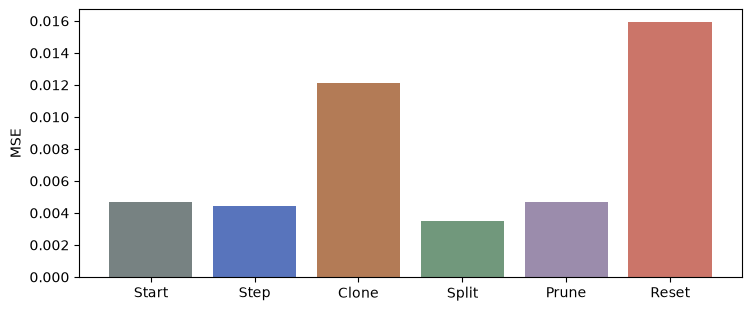

In [4]:
fig = demo.density_chart("en")
display(fig)
plt.close(fig)

## Pruning and resetting have different effects

**Pruning** removes a splat altogether. Our threshold $0.03$ applies to center opacity. The speck has $o=0.015<0.03$, so it disappears. The large splat remains useful. The list shrinks and the error stays close to its initial value, at $0.00467882$. It actually **increased** slightly. A tiny contribution still has an effect.

An **opacity reset** leaves centers and shapes in place. The new value $o'=\min(o,0.01)$ is the smaller of the old $o$ and one hundredth. For instance $0.77$ becomes $0.01$, whereas $0.004$ stays $0.004$. When the splats are faint, more light passes through and a hidden layer has a chance to contribute. Optimization can build useful opacities back up. Immediately after resetting, the image is almost white and MSE is $0.01592582$. Applying the pruning threshold of $0.03$ at this moment would remove every splat. Both order and timing matter in a full training run.

In [5]:
for action in ("clone","split","prune","reset"):
    scene = sr.density_edit(initial, action)
    n = len(scene["splats"])
    print(f"{action:6s} N={n}, bytes={56*n}, MSE={sr.density_loss(scene):.8f}")
assert len(sr.density_edit(sr.density_edit(initial, "reset"), "prune")["splats"]) == 0

clone  N=3, bytes=168, MSE=0.01214659
split  N=3, bytes=168, MSE=0.00347211
prune  N=1, bytes=56, MSE=0.00467882
reset  N=2, bytes=112, MSE=0.01592582


## How a training loop makes the decision

In one adaptive pass of the experiment we first compute all gradients in the old scene. Any splat with $o<0.03$ is marked for removal. For the others we compare the magnitude of their horizontal gradient with $0.001$. For the broad splat $|-0.00304635|>0.001$. This flags an area where moving the center can appreciably change the loss. It measures sensitivity to a shift, with no guarantee that this is where a detail is missing.

Now we need a copy or two children. In this experiment a horizontal scale above $0.32$ counts as broad. Since $0.63>0.32$, the splat is split. A sufficiently narrow one with the same strong signal would be cloned. A budget of 16 splats keeps each step easy to inspect. After the first adaptive pass the broad splat has become two and the faint speck is gone, so the count is two again. The MSE is different, about $0.00348773$. A splat counter alone would miss this restructuring.

The original 3DGS implementation accumulates a signal for **visible** splats over training steps. It takes lengths of the two-component screen-center gradients and averages them over observations. Size is compared with scene extent. A split samples children around the parent's center using its shape and orientation. The code can also prune excessively large footprints. Our single-camera version uses the world-$x$ derivative, deterministic child offsets, and explicit controls. The example thresholds belong to its particular coordinates and loss. [Algorithm in the paper](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) and [parameter operations in the reference implementation](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/gaussian_model.py).

In [6]:
adaptive = sr.density_pass(initial)
print([(s["center"][0],s["scales"][0],s["opacity"]) for s in adaptive["splats"]])
assert len(adaptive["splats"]) == len(initial["splats"])
assert sr.density_loss(adaptive) < sr.density_loss(initial)
for _ in range(8):
    adaptive = sr.density_step(adaptive)
print("8 steps:", sr.density_loss(adaptive))

[(-0.5695, 0.39375, 0.77), (0.24950000000000003, 0.39375, 0.77)]


8 steps: 0.0028990938514448354


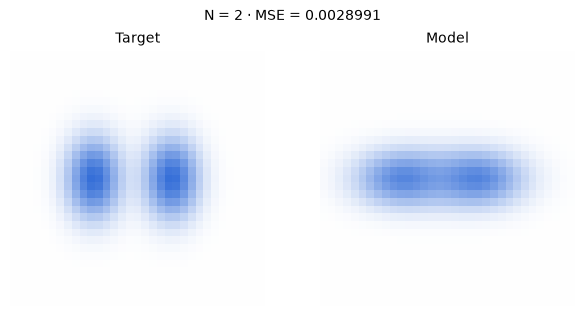

In [7]:
fig = demo.density_figure("en", operation="adaptive", steps=8)
display(fig)
plt.close(fig)

## Experiments and worked answers

How much memory did a clone add? Why can the change in total GPU memory use not be read directly from that number?

<details><summary>Worked answer</summary>

A splat stores three coordinates, three scales, four quaternion components, three color channels, and an opacity. That is $3+3+4+3+1=14$ numbers. One float32 occupies $32/8=4$ bytes. A clone adds $14\cdot4=56$ bytes of parameter payload. Two splats take 112 bytes and three take 168. A full model adds SH coefficients, gradients, optimizer state, tile lists, and temporary images. Text JSON also contains characters and keys. Here we measure exactly the numerical payload of the chosen representation.

</details>